Хiд виконання роботи:
1. Початковi 2D-данi представити графiчно.
2. Розбити данi на навчальний, перевiрочний та тестовий набори. Перевiрочний набiр використати для налаштування гiперпараметрiв. Тестовий набiр використати для остаточної оцiнки якостi моделей.

Навести приклад границi рiшень decision boundaries на основi окремої моделi та ансамблю.
Розрахувати значення змiщення та дисперсiї для окремої моделi та ансамблю.

Тип ансамблю: StackingClassifier.
Розглянути рiзнi значення параметрiв final_estimator та stack_method.
Початковi данi:
sklearn.datasets.fetch_covtype - це надвеликий набiр.
Якщо не вийде працювати з ним цiлком, достатньо сформувати з нього пiднабiр, обираючи елементи випадковим чином. Моделi будувати на сформованому пiднаборi.

In [1]:
import numpy as np
import seaborn as sns
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import StandardScaler

ds = fetch_covtype()

In [2]:
#нам довзолено використовувати лише частину датасету, для прискорення виконання роботи, тож так і зробимо
n_samp = 10_000
n_feat = 54#10
np.random.seed(42)
sample_indices = np.random.choice(len(ds["data"]), n_samp, replace=False)
sample_features = np.random.choice(len(ds["feature_names"]), n_feat, replace = False)

X = ds["data"][sample_indices]
X = X[:, sample_features]
y = ds["target"][sample_indices]

In [3]:
#тільки якщо мала розмірність
# import pandas as pd
# plot_df = pd.DataFrame(data = X)
# plot_df["target"] = y
# sns.pairplot(plot_df, hue = "target")

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import average_precision_score, classification_report

scaler = StandardScaler()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
X_train = scaler.fit_transform(X_train)
X_test, X_eval, y_test, y_eval = train_test_split(
    X_test, y_test, test_size=0.5, random_state=42)
X_test = scaler.transform(X_test)
X_eval = scaler.transform(X_eval)

estimators = [
    ('dt', DecisionTreeClassifier(max_depth = 4, min_samples_split = 0.1, random_state = 42)),
    ('svm', LinearSVC())
]
final_model = DecisionTreeClassifier(max_depth = 4, min_samples_split = 0.1, random_state = 42)
base_model = DecisionTreeClassifier(max_depth = 4, min_samples_split = 0.1, random_state = 42)

#ансамбль
stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=final_model,
    stack_method='auto',
    cv=3,
    n_jobs=-1
)

base_model.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

predict_base = base_model.predict(X_eval)
predict_stack = stacking_clf.predict(X_eval)
print('базова модель')
print(classification_report(y_eval, predict_base.reshape(-1, 1)))
print('ансамбль')
print(classification_report(y_eval, predict_stack.reshape(-1, 1)))


базова модель
              precision    recall  f1-score   support

           1       0.64      0.59      0.61       352
           2       0.69      0.80      0.74       497
           3       0.47      0.85      0.61        53
           4       0.00      0.00      0.00         4
           5       0.00      0.00      0.00        19
           6       0.00      0.00      0.00        45
           7       0.00      0.00      0.00        30

    accuracy                           0.65      1000
   macro avg       0.26      0.32      0.28      1000
weighted avg       0.59      0.65      0.61      1000

ансамбль
              precision    recall  f1-score   support

           1       0.66      0.71      0.69       352
           2       0.74      0.74      0.74       497
           3       0.50      0.94      0.65        53
           4       0.00      0.00      0.00         4
           5       0.00      0.00      0.00        19
           6       0.00      0.00      0.00        45
 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Побудуємо decision boundaries

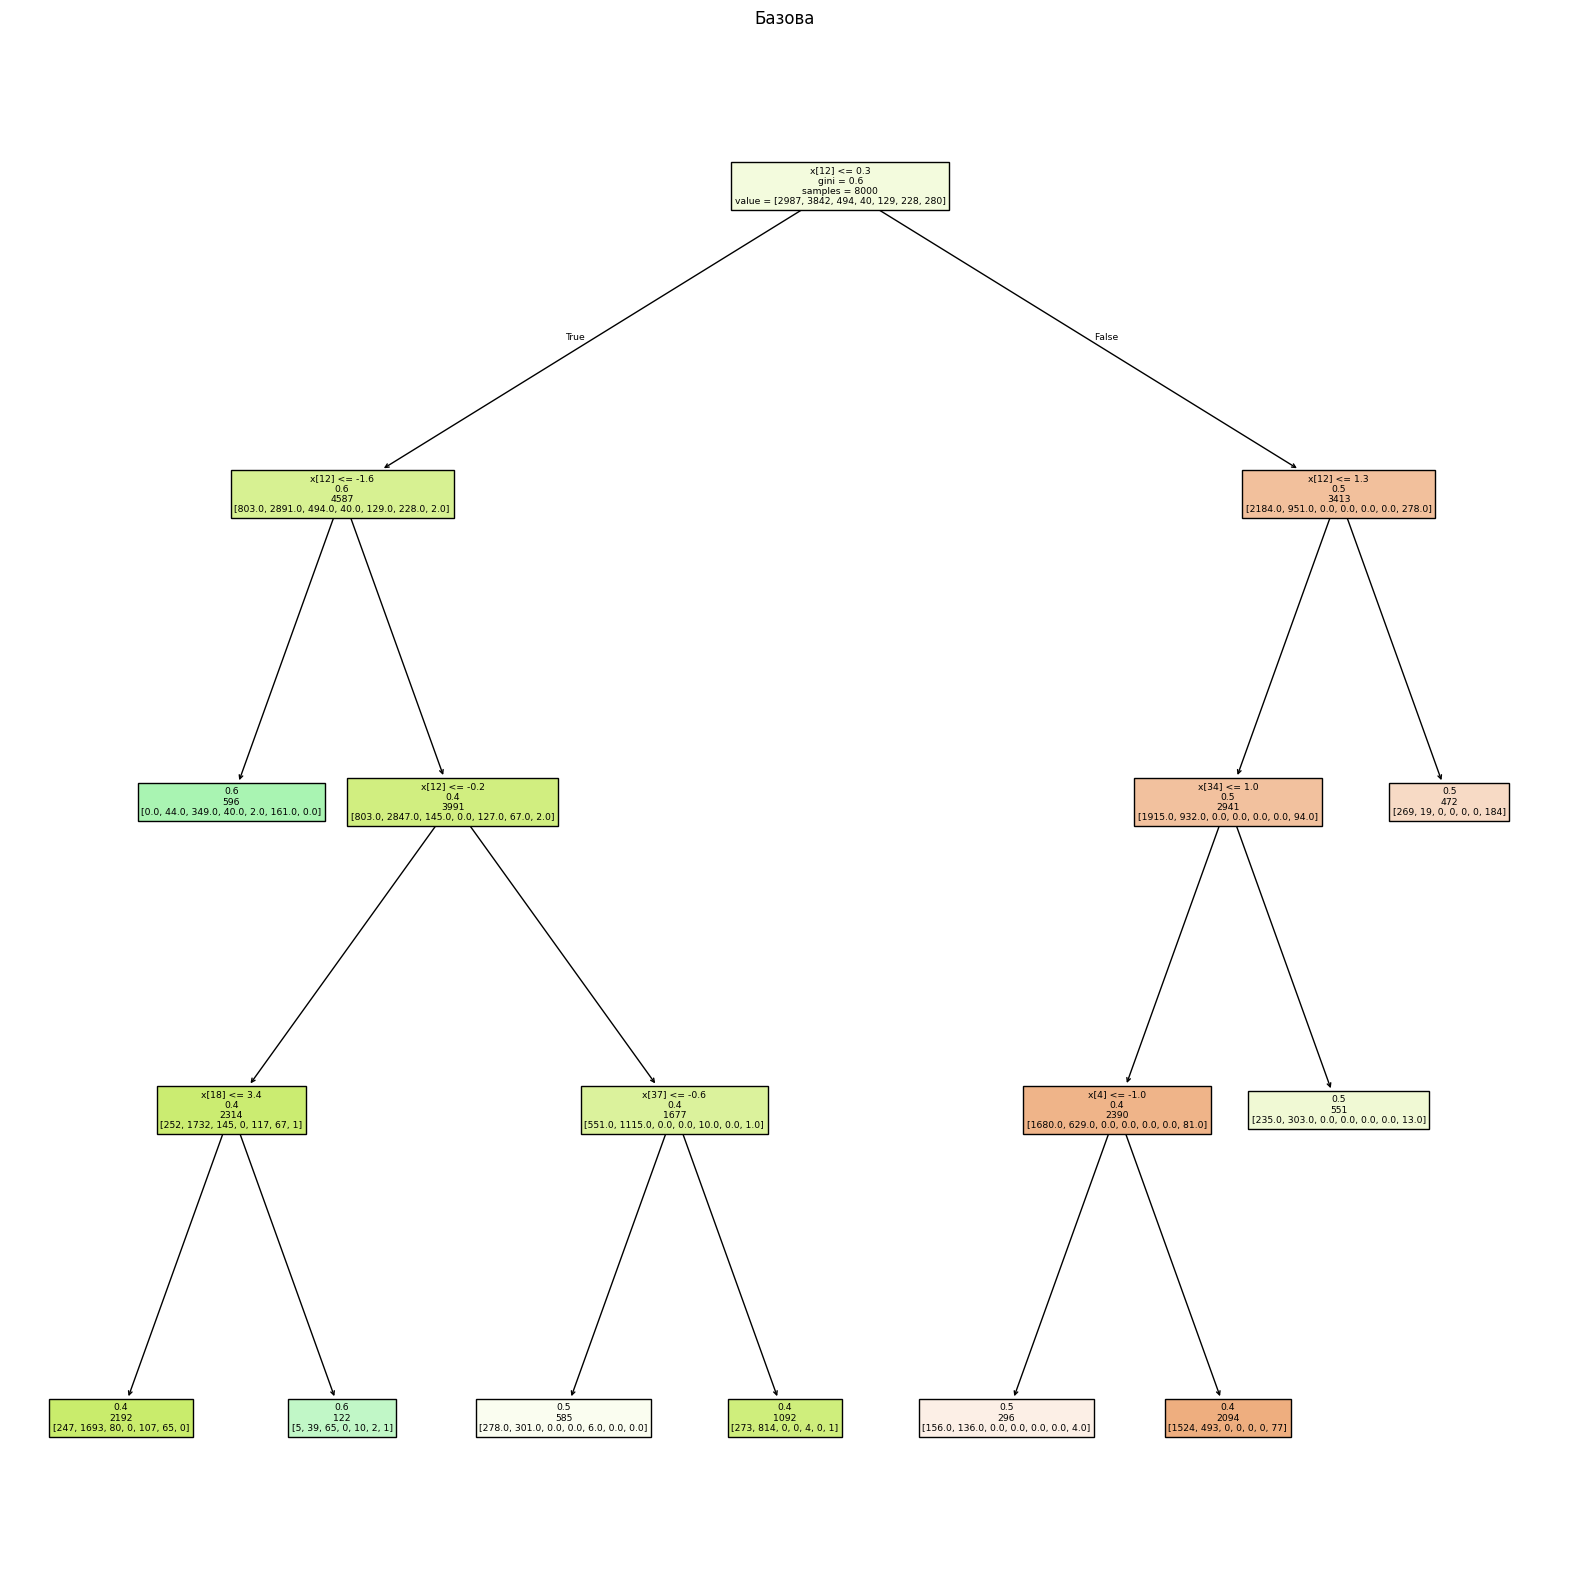

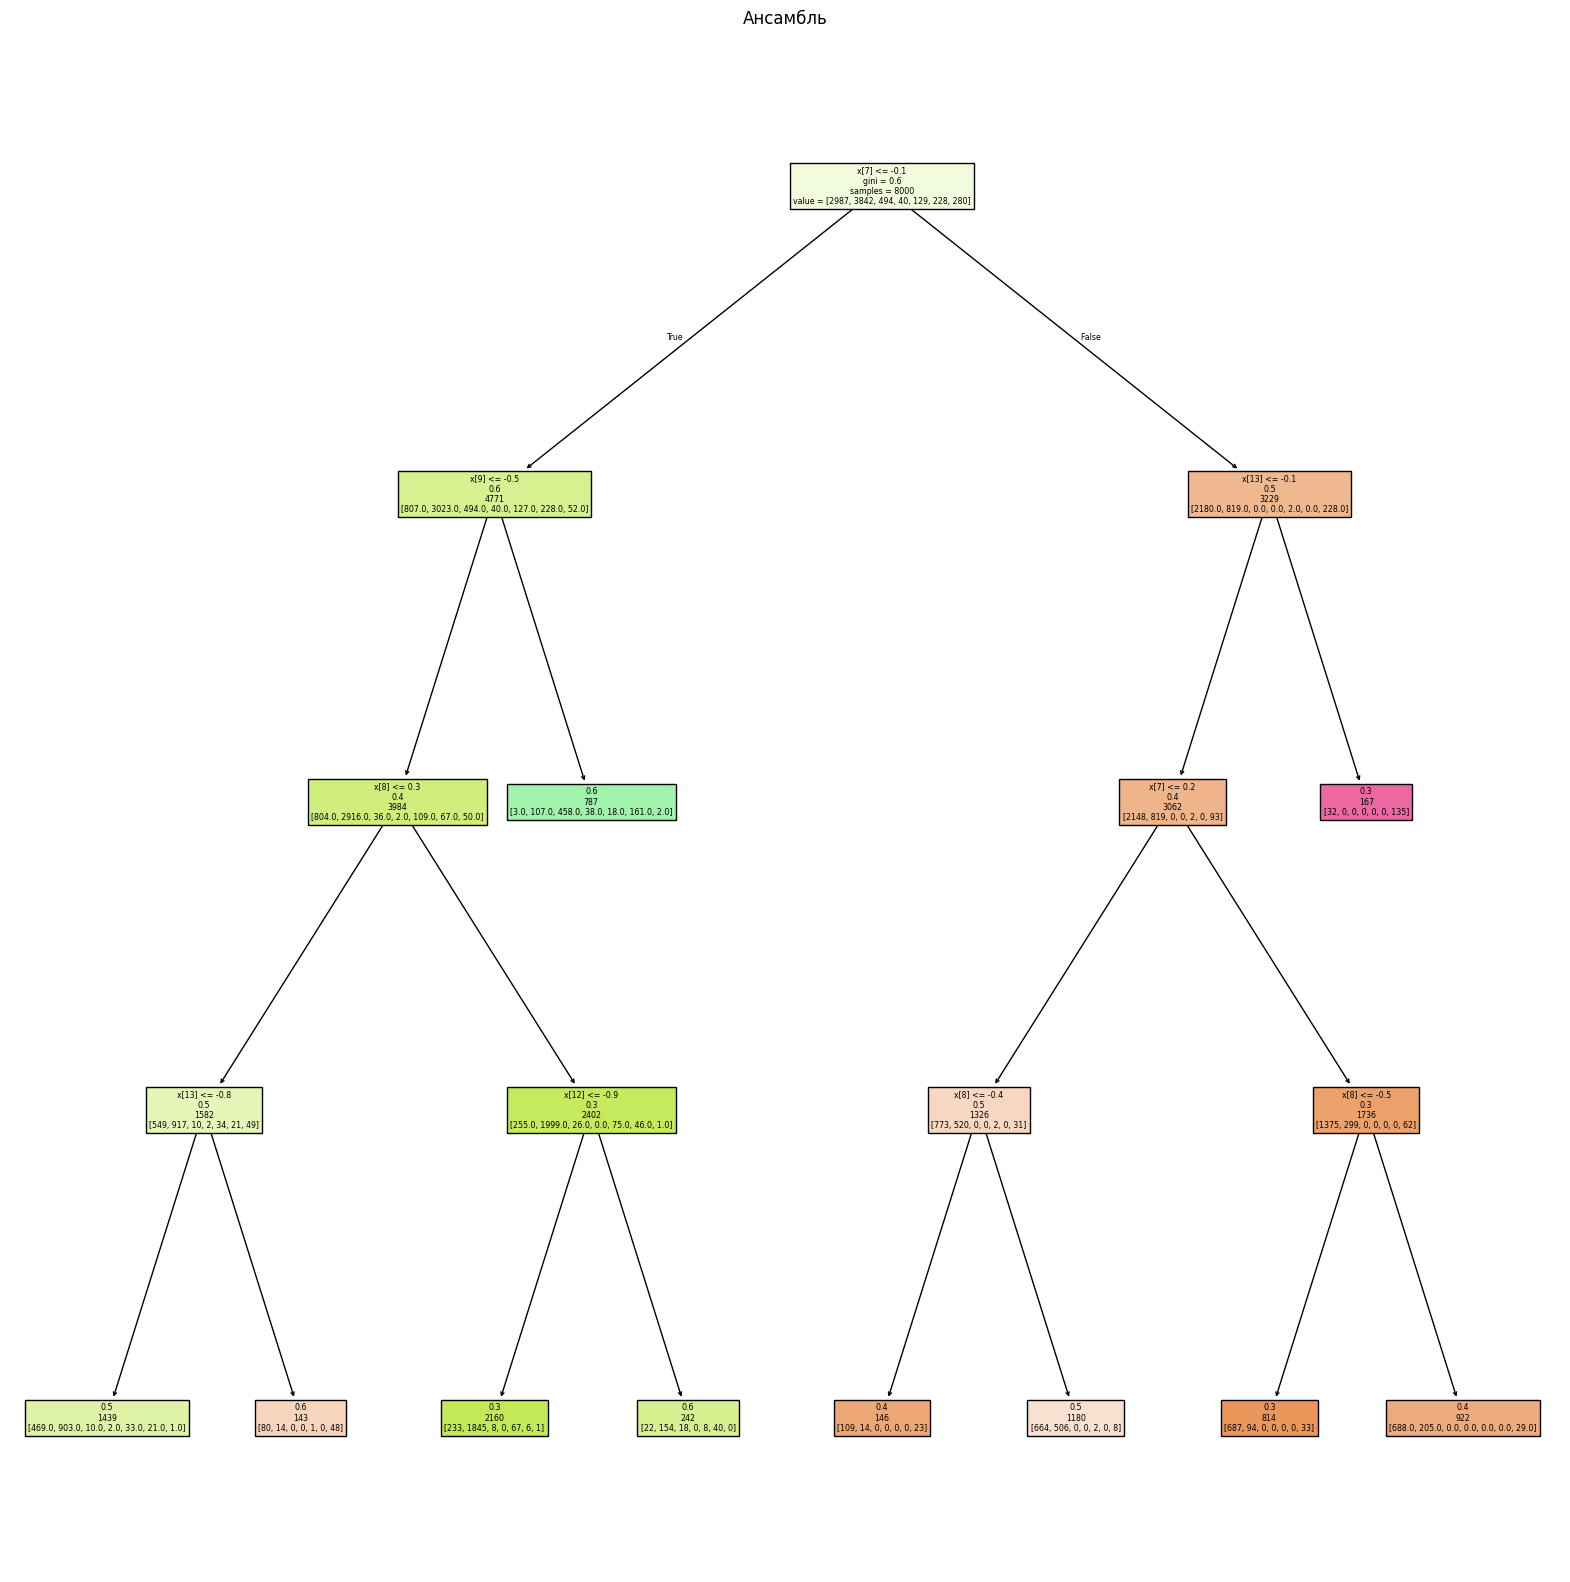

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize = (20,20))
plot_tree(base_model, filled=True, precision = 1, label = 'root')
plt.title('Базова')
plt.show()
plt.figure(figsize = (20,20))
plot_tree(stacking_clf.final_estimator_, filled=True, precision = 1, label = 'root')
plt.title('Ансамбль')
plt.show()

In [6]:
# !pip install mlxtend

In [7]:
from mlxtend.evaluate import bias_variance_decomp
avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(base_model, X_train, y_train, X_test, y_test, num_rounds = 20, random_seed = 42)
print("середній лос, за яким рахували    середнє зміщення    середня дисперсія")
print("статистики базової моделі")
print(avg_expected_loss, avg_bias, avg_var)
avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(stacking_clf, X_train, y_train, X_test, y_test, num_rounds = 20, random_seed = 42)
print("статистики ансамблю")
print(avg_expected_loss, avg_bias, avg_var)

середній лос, за яким рахували    середнє зміщення    середня дисперсія
статистики базової моделі
0.32795 0.327 0.06705000000000001
статистики ансамблю
0.29864999999999997 0.293 0.08545


Зробити висновки. Чи краще на заданих даних виконується ансамбль порiвняно з iндивiдуальними моделями?

Навчання ансамблю відбувається значно повільніше, адже доводиться вчити n моделей, замість однієї. Ансамбль показує себе набагато краще за використання однієї моделі. Ансамбль має значно менше зміщення та трошки більшу дисперсію, в порівнянні з однією моделлю. Є не один приклад, як люди вигравали кагли просто взявши правильний ансамбль з 20 моделей